Accuracy of SVM classifier: 1.00


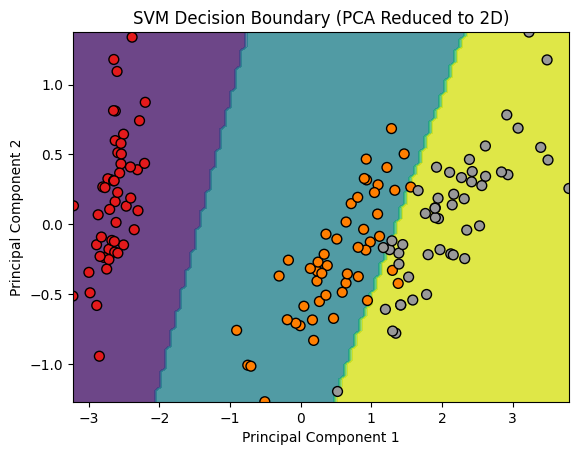

In [1]:
import numpy as np
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

data = load_iris()
X = data.data
y = data.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

svm_clf = SVC(kernel='linear', random_state=42)
svm_clf.fit(X_train, y_train)

y_pred = svm_clf.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)

print(f'Accuracy of SVM classifier: {accuracy:.2f}')

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

svm_clf_2d = SVC(kernel='linear', random_state=42)
svm_clf_2d.fit(X_pca, y)

xx, yy = np.meshgrid(
    np.linspace(X_pca[:, 0].min(), X_pca[:, 0].max(), 100),
    np.linspace(X_pca[:, 1].min(), X_pca[:, 1].max(), 100)
)

Z = svm_clf_2d.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

plt.contourf(xx, yy, Z, alpha=0.8)
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y, edgecolors='k', cmap=plt.cm.Set1, s=50)
plt.title("SVM Decision Boundary (PCA Reduced to 2D)")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.show()